In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/fraud_oracle.csv")
print(df.shape)
print("Boş xana:", df.isnull().sum().sum())
print(df["FraudFound_P"].value_counts())
print((df["FraudFound_P"].value_counts(normalize=True) * 100).round(2))
df.head()

(15420, 33)
Boş xana: 0
FraudFound_P
0    14497
1      923
Name: count, dtype: int64
FraudFound_P
0    94.01
1     5.99
Name: proportion, dtype: float64


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


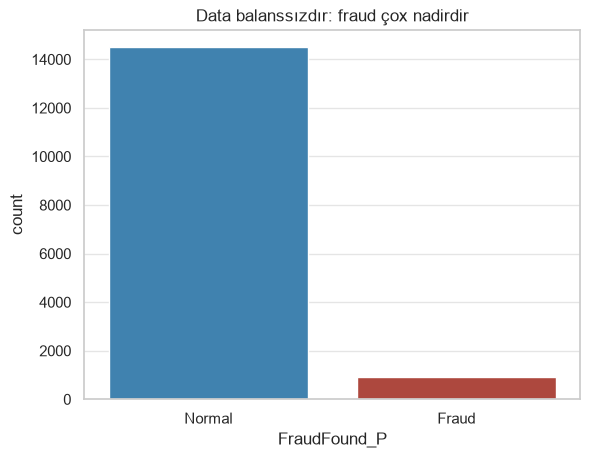

In [5]:
sns.countplot(x="FraudFound_P", hue="FraudFound_P", data=df,
              palette=["#2e86c1", "#c0392b"], legend=False)
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.title("Data balanssızdır: fraud çox nadirdir")
plt.show()

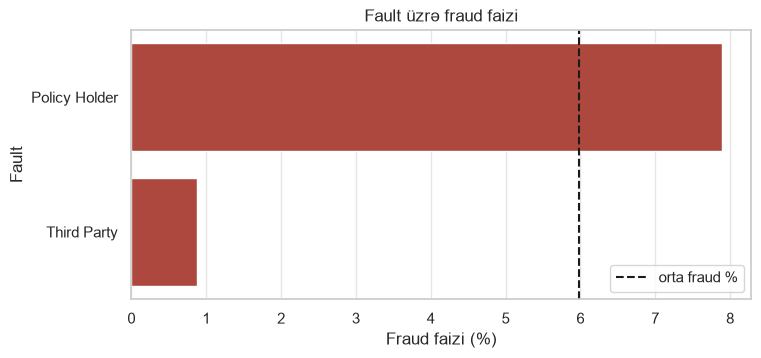

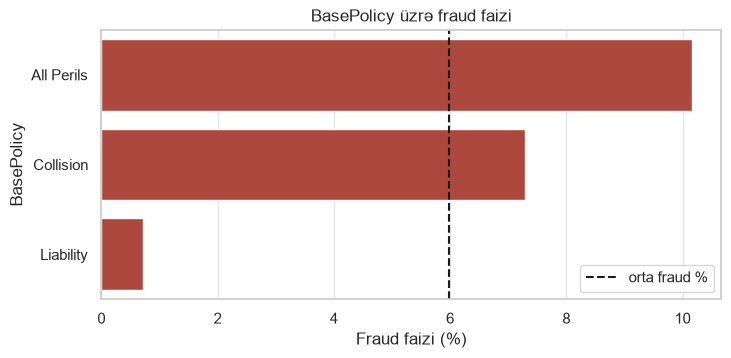

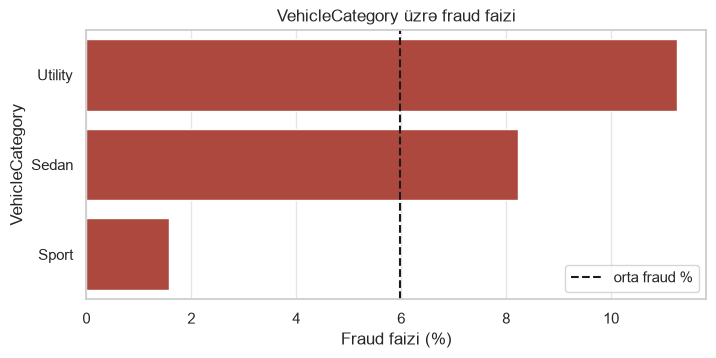

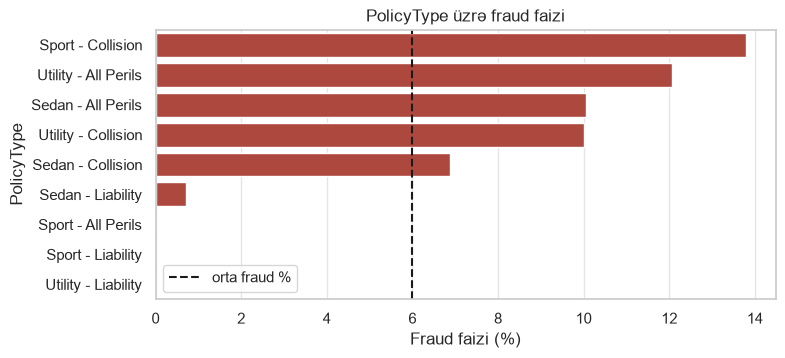

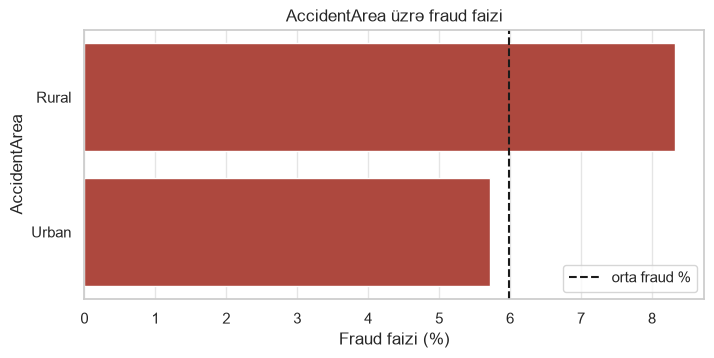

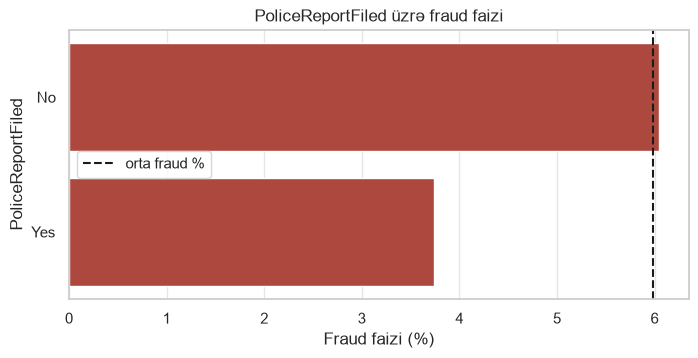

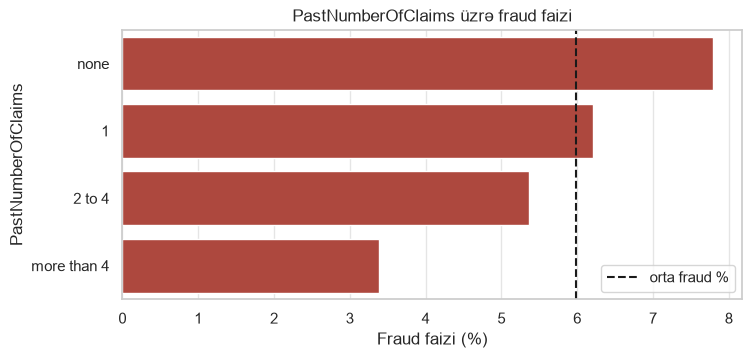

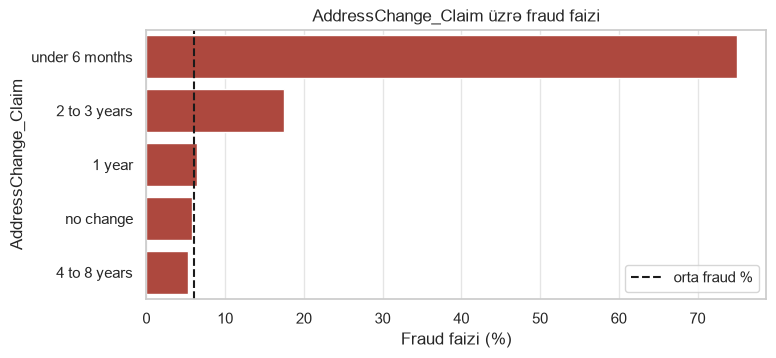

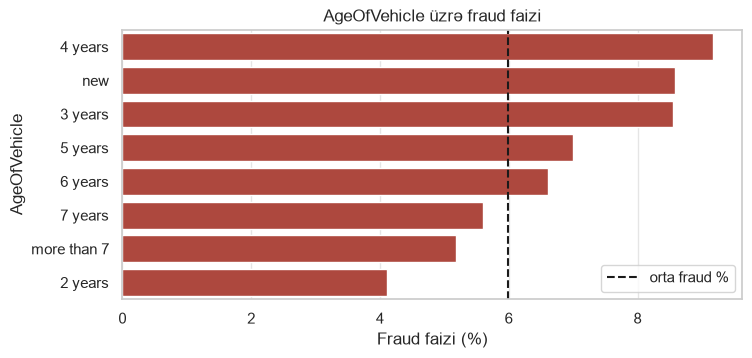

In [6]:
def fraud_rate(col):
    r = df.groupby(col)["FraudFound_P"].mean().sort_values(ascending=False) * 100
    plt.figure(figsize=(8, 3.5))
    sns.barplot(x=r.values, y=r.index, color="#c0392b")
    plt.axvline(df["FraudFound_P"].mean() * 100, color="k", ls="--", label="orta fraud %")
    plt.xlabel("Fraud faizi (%)")
    plt.title(f"{col} üzrə fraud faizi")
    plt.legend()
    plt.show()

for c in ["Fault", "BasePolicy", "VehicleCategory", "PolicyType", "AccidentArea",
          "PoliceReportFiled", "PastNumberOfClaims", "AddressChange_Claim", "AgeOfVehicle"]:
    fraud_rate(c)

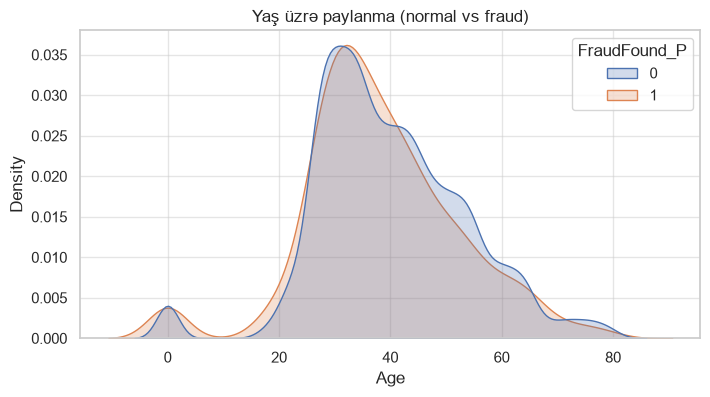

In [7]:
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df, x="Age", hue="FraudFound_P", common_norm=False, fill=True)
plt.title("Yaş üzrə paylanma (normal vs fraud)")
plt.show()